<a href="https://colab.research.google.com/github/naveennkgamer/RCMS-Clientview/blob/main/AI_INHERITED_RETINAL_DISEASES.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install tensorflow opencv-python matplotlib reportlab

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 22.9 MB/s eta 0:00:00


In [ ]:
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))

[]


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving syntheye100_synthetic_faf.zip to syntheye100_synthetic_faf.zip


In [ ]:
import zipfile

zip_ref = zipfile.ZipFile(
    "syntheye100_synthetic_faf.zip",
    'r'
)

zip_ref.extractall()
zip_ref.close()

print("✅ Dataset Extracted")

✅ Dataset Extracted


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'MYO7A', 'EYS', 'RS1', 'TIMP3', 'RPGR', 'PRPH2', 'syntheye100_synthetic_faf.zip', 'BEST1', 'USH2A', 'EFEMP1', 'ABCA4', 'sample_data']


In [ ]:
import os
import shutil

clean_path = "/content/retina_dataset"

# Create new folder
if not os.path.exists(clean_path):
    os.makedirs(clean_path)

valid_folders = [
    "ABCA4",
    "BEST1",
    "EFEMP1",
    "EYS",
    "MYO7A",
    "PRPH2",
    "RPGR",
    "RS1",
    "TIMP3",
    "USH2A"
]

# Move valid folders
for folder in valid_folders:
    src = f"/content/{folder}"
    dst = f"{clean_path}/{folder}"

    if os.path.exists(src):
        shutil.move(src, dst)

print("✅ Clean dataset created")

✅ Clean dataset created


In [ ]:
import os

print(os.listdir("/content/retina_dataset"))

['MYO7A', 'EYS', 'RS1', 'TIMP3', 'RPGR', 'PRPH2', 'BEST1', 'USH2A', 'EFEMP1', 'ABCA4']


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = 224
BATCH_SIZE = 32

dataset_path = "/content/retina_dataset"

datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_data = datagen.flow_from_directory(
    dataset_path,
    target_size=(224,224),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training"
)

val_data = datagen.flow_from_directory(
    dataset_path,
    target_size=(224,224),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation"
)

print("✅ Classes:")
print(train_data.class_indices)

Found 800 images belonging to 10 classes.
Found 200 images belonging to 10 classes.
✅ Classes:
{'ABCA4': 0, 'BEST1': 1, 'EFEMP1': 2, 'EYS': 3, 'MYO7A': 4, 'PRPH2': 5, 'RPGR': 6, 'RS1': 7, 'TIMP3': 8, 'USH2A': 9}


In [ ]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import GlobalAveragePooling2D
from tensorflow.keras.models import Model

base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224,224,3)
)

x = base_model.output

x = GlobalAveragePooling2D()(x)

x = Dense(256, activation="relu")(x)

predictions = Dense(
    train_data.num_classes,
    activation="softmax"
)(x)

model = Model(
    inputs=base_model.input,
    outputs=predictions
)

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("✅ Model Ready")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
✅ Model Ready


In [ ]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)

Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 294s 10s/step - accuracy: 0.6087 - loss: 1.1919 - val_accuracy: 0.1000 - val_loss: 2.6103
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 222s 9s/step - accuracy: 0.8888 - loss: 0.3216 - val_accuracy: 0.1000 - val_loss: 3.1908
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 226s 9s/step - accuracy: 0.9375 - loss: 0.1763 - val_accuracy: 0.1000 - val_loss: 2.4961
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 221s 9s/step - accuracy: 0.9575 - loss: 0.1145 - val_accuracy: 0.1000 - val_loss: 2.6748
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 227s 9s/step - accuracy: 0.9762 - loss: 0.0801 - val_accuracy: 0.1000 - val_loss: 4.2603
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 230s 9s/step - accuracy: 0.9600 - loss: 0.1145 - val_accuracy: 0.1000 - val_loss: 5.7311
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 229s 9s/step - accuracy: 0.9613 - loss: 0.1211 - val_accuracy: 0.1000 - val_loss: 8.9979
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 227s 9s/step - accuracy: 0.9775 - loss: 0.0727 - val_accuracy: 0.1000 - 

In [ ]:
model.save("retinal_model.h5")

print("✅ Model saved")

✅ Model saved


In [ ]:
model.save("retinal_model.h5")

print("✅ Model saved")

✅ Model saved


In [ ]:
!pip install tensorflow opencv-python matplotlib reportlab

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 38.3 MB/s eta 0:00:00


In [ ]:
from google.colab import files

files.upload()

In [ ]:
import os

print(os.listdir("/content/retina_dataset/ABCA4")[:5])

['image95.png', 'image76.png', 'image71.png', 'image31.png', 'image29.png']


In [ ]:
image_path = "/content/retina_dataset/ABCA4/image44.png"

In [ ]:
import numpy as np
import cv2

IMG_SIZE = 224

classes = [
'ABCA4',
'BEST1',
'EFEMP1',
'EYS',
'MYO7A',
'PRPH2',
'RPGR',
'RS1',
'TIMP3',
'USH2A'
]

image_path = "/content/retina_dataset/ABCA4/image44.png"

img = cv2.imread(image_path)

img = cv2.resize(img, (224,224))

img_array = img / 255.0

img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)

class_index = np.argmax(prediction)

predicted_class = classes[class_index]

confidence = prediction[0][class_index]

print("✅ Prediction:", predicted_class)
print("✅ Confidence:", confidence)

1/1 ━━━━━━━━━━━━━━━━━━━━ 15s 15s/step
✅ Prediction: RS1
✅ Confidence: 0.14545758


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


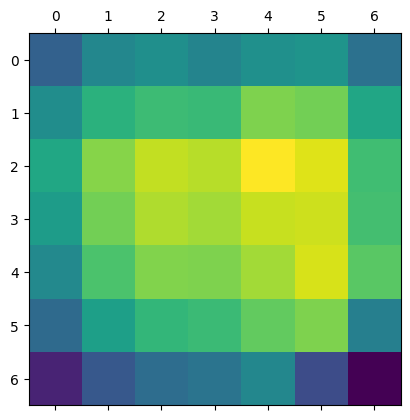

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt

last_conv_layer = model.get_layer("top_conv")

grad_model = tf.keras.models.Model(
    [model.inputs],
    [last_conv_layer.output, model.output]
)

with tf.GradientTape() as tape:

    conv_outputs, predictions = grad_model(img_array)

    class_channel = predictions[:, class_index]

grads = tape.gradient(class_channel, conv_outputs)

pooled_grads = tf.reduce_mean(grads, axis=(0,1,2))

conv_outputs = conv_outputs[0]

heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]

heatmap = tf.squeeze(heatmap)

heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)

heatmap = heatmap.numpy()

plt.matshow(heatmap)

plt.show()

In [ ]:
heatmap = cv2.resize(heatmap, (224,224))

heatmap = np.uint8(255 * heatmap)

heatmap = cv2.applyColorMap(
    heatmap,
    cv2.COLORMAP_JET
)

superimposed_img = heatmap * 0.4 + img

cv2.imwrite(
    "xai_output.jpg",
    superimposed_img
)

print("✅ XAI Image Saved")

✅ XAI Image Saved


In [ ]:
from reportlab.platypus import SimpleDocTemplate
from reportlab.platypus import Paragraph
from reportlab.platypus import Spacer
from reportlab.platypus import Image
from reportlab.lib.styles import getSampleStyleSheet

from datetime import datetime

styles = getSampleStyleSheet()

# Get current date
current_date = datetime.now().strftime("%d-%m-%Y %H:%M")

# Optional patient details
patient_name = "Sample Patient"
patient_id = "RP001"
model_name = "EfficientNetB0 Retina Model"

# Create PDF
pdf = SimpleDocTemplate("retina_detailed_report.pdf")

story = []

# Title
story.append(
    Paragraph(
        "Retinal Disease Detection Report",
        styles['Title']
    )
)

story.append(Spacer(1,20))

# Patient Details
story.append(
    Paragraph(
        f"<b>Patient Name:</b> {patient_name}",
        styles['Normal']
    )
)

story.append(
    Paragraph(
        f"<b>Patient ID:</b> {patient_id}",
        styles['Normal']
    )
)

story.append(
    Paragraph(
        f"<b>Date:</b> {current_date}",
        styles['Normal']
    )
)

story.append(Spacer(1,15))

# Prediction Results
story.append(
    Paragraph(
        "<b>Prediction Results</b>",
        styles['Heading2']
    )
)

story.append(
    Paragraph(
        f"<b>Predicted Disease:</b> {predicted_class}",
        styles['Normal']
    )
)

story.append(
    Paragraph(
        f"<b>Confidence Score:</b> {confidence:.2f}",
        styles['Normal']
    )
)

story.append(
    Paragraph(
        f"<b>Model Used:</b> {model_name}",
        styles['Normal']
    )
)

story.append(Spacer(1,15))

# Interpretation Section
story.append(
    Paragraph(
        "<b>Clinical Interpretation</b>",
        styles['Heading2']
    )
)

story.append(
    Paragraph(
        f"The AI system detected features consistent with "
        f"<b>{predicted_class}</b>. "
        f"The highlighted regions in the XAI image indicate "
        f"areas that contributed most to the prediction.",
        styles['Normal']
    )
)

story.append(Spacer(1,15))

# Recommendation Section
story.append(
    Paragraph(
        "<b>Recommendation</b>",
        styles['Heading2']
    )
)

story.append(
    Paragraph(
        "This automated result is intended for screening purposes only. "
        "Consult an ophthalmologist for professional diagnosis "
        "and clinical confirmation.",
        styles['Normal']
    )
)

story.append(Spacer(1,20))

# Original Image
story.append(
    Paragraph(
        "<b>Original Retina Image</b>",
        styles['Heading2']
    )
)

story.append(Spacer(1,10))

story.append(
    Image(
        image_path,
        width=250,
        height=250
    )
)

story.append(Spacer(1,20))

# XAI Image
story.append(
    Paragraph(
        "<b>XAI Visualization (Highlighted Regions)</b>",
        styles['Heading2']
    )
)

story.append(Spacer(1,10))

story.append(
    Image(
        "xai_output.jpg",
        width=250,
        height=250
    )
)

# Build PDF
pdf.build(story)

print("✅ Detailed PDF Report Generated")

✅ Detailed PDF Report Generated


In [ ]:
files.download("retina_detailed_report.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>